Below cell contains starter code to generate the initial centers.
Please do not change anything apart from the student ID.
The initial centers will be in a dictionary with keys being 'k' and value being the centers.

In [1]:
from precode import * 

data = np.load('AllSamples.npy')
initial_centers = {}

for k in range(2, 11):
    centers = initial_S2("4853", k)  # please replace 0111 with your last four digit of your ID
    initial_centers[k] = centers 
print(initial_centers)
#enter your last 4 digits of student id instead of 0000

{2: array([7.83816267, 2.49139275]), 3: array([6.65537695, 1.30451652]), 4: array([7.59763505, 7.93924   ]), 5: array([4.32239695, 0.33088885]), 6: array([7.33424973, 2.97894225]), 7: array([4.43990951, 3.70495907]), 8: array([2.5366924 , 2.24222672]), 9: array([5.6651354, 2.7313015]), 10: array([1.91568768, 6.83080871])}


Print the last 4 digits of your student id as string in the cell
below. Please make sure to only have one print statement in the cell below.

In [2]:
### TEST FUNCTION: test_print_id
# DO NOT REMOVE THE LINE ABOVE
print('4853') #add your ID again here

4853


Add your code for computing the kMeans final centroids and loss functions in the code block below.

In [3]:
# Generate the remaining Strategy 2 initial centroids.
def generate_strategy2_centroids(data, first_centroid, k):
    centroids = [first_centroid.copy()]

    while len(centroids) < k:
        selected_centroids = np.array(centroids)

        # Calculate the Euclidean distance from every data point
        # to every centroid already selected.
        distances = np.sqrt(
            np.sum(
                (
                    data[:, np.newaxis, :]
                    - selected_centroids[np.newaxis, :, :]
                ) ** 2,
                axis=2
            )
        )

        # Calculate each point's average distance to the selected centroids.
        average_distances = np.mean(distances, axis=1)

        # Exclude points that have already been selected as centroids.
        duplicate_mask = np.any(distances == 0, axis=1)
        average_distances[duplicate_mask] = -np.inf

        # Select the point with the largest average distance.
        next_centroid_index = np.argmax(average_distances)
        centroids.append(data[next_centroid_index].copy())

    return np.array(centroids)


# Implement K-means using the Strategy 2 initial centers.
def run_kmeans(data, initial_centroids):
    centroids = initial_centroids.copy()
    k = len(centroids)

    while True:
        # Calculate the squared Euclidean distance from every point
        # to every centroid.
        distances = np.sum(
            (
                data[:, np.newaxis, :]
                - centroids[np.newaxis, :, :]
            ) ** 2,
            axis=2
        )

        # Assign each point to its nearest centroid.
        labels = np.argmin(distances, axis=1)

        # Recompute each centroid from the points assigned to it.
        new_centroids = []

        for cluster_index in range(k):
            cluster_points = data[labels == cluster_index]

            # An empty cluster usually indicates an upstream problem.
            if len(cluster_points) == 0:
                raise ValueError(
                    f"Empty cluster encountered for cluster {cluster_index}"
                )

            new_centroids.append(
                np.mean(cluster_points, axis=0)
            )

        new_centroids = np.array(new_centroids)

        # Stop only when the centroids are exactly unchanged.
        if np.array_equal(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    # Recompute assignments using the final centroids.
    distances = np.sum(
        (
            data[:, np.newaxis, :]
            - centroids[np.newaxis, :, :]
        ) ** 2,
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    # Compute the K-means objective function:
    # sum of squared distances to each point's assigned centroid.
    loss = np.sum(
        (data - centroids[labels]) ** 2
    )

    return centroids, labels, float(loss)


# Store the Strategy 2 initial and final results for k = 2 through 10.
strategy2_initial_centroids = {}
final_centroids = {}
final_labels = {}
losses = {}

for k in range(2, 11):
    strategy2_centroids = generate_strategy2_centroids(
        data,
        initial_centers[k],
        k
    )

    strategy2_initial_centroids[k] = strategy2_centroids

    centroids, labels, loss = run_kmeans(
        data,
        strategy2_centroids
    )

    final_centroids[k] = centroids
    final_labels[k] = labels
    losses[k] = loss

Please use the following cell to print all the final 
centeriods for k in the range of 2 to 10, both inclusive.

Notes:
The centeriods should have the following format: 
[[x1,y1],[x2,y2],[x3,y3]][[x_1,y_1],[x_2,y_2],[x_3,y_3]]

The order of the centeriod does not matter 
but do NOT change the order for x and y coordinate.

Please print the centroids from k=2 to k=10 in order and each on a new line.
Do not print anything else in the code cell below.

Example:  
[[x1, y1], [x2, y2]]

[[x1, y1], [x2, y2], [x3, y3]]

 .

 .
 
 .

 [[x1,y1]..[x9,y9]]

In [4]:
### TEST FUNCTION: test_project2_part2_1cen
# DO NOT REMOVE THE LINE ABOVE

print(final_centroids[2].tolist())
print(final_centroids[3].tolist())
print(final_centroids[4].tolist())
print(final_centroids[5].tolist())
print(final_centroids[6].tolist())
print(final_centroids[7].tolist())
print(final_centroids[8].tolist())
print(final_centroids[9].tolist())
print(final_centroids[10].tolist())

[[5.000562341588762, 2.4854274751531933], [4.852611930287174, 7.271641711202775]]
[[5.477400388679034, 2.254981027984723], [2.5614644894663545, 6.088613382895479], [6.497249620849709, 7.522972929895171]]
[[6.6259253846324615, 7.576149167622678], [3.2285300905383707, 2.5240486292057867], [2.9054774114449513, 6.905122763339948], [7.252626831256577, 2.4001582635520533]]
[[7.252626831256577, 2.4001582635520533], [7.756483249146484, 8.556689279063415], [2.601232962568677, 6.91610505751996], [3.2125746077046626, 2.496580865799525], [5.402525077573915, 6.736361752187993]]
[[7.414192434680615, 2.3216911383868664], [5.464277356727894, 6.837713536435891], [3.145061482959145, 0.9077065486588153], [7.756483249146484, 8.556689279063415], [3.4955665791995627, 3.5661123157286907], [2.5633381461259046, 6.978224800606624]]
[[5.053595758651041, 4.007145374859899], [8.398707529316267, 8.925497059743181], [2.681986334188929, 2.094615867800809], [5.357627458195424, 7.071359743770291], [7.556167822397726, 2

Please use the following cell to print all the final loss functions for k in the range of 2 to 10, both inclusive.

Notes:
Print the loss functions for every value of k in a new line and in order.
Do not print anything else in the code cell below.

Example: 

L1 

L2 

L3 

.

.

.

L9

In [5]:
### TEST FUNCTION: test_project2_part2_loss
# DO NOT REMOVE THE LINE ABOVE

print(losses[2])
print(losses[3])
print(losses[4])
print(losses[5])
print(losses[6])
print(losses[7])
print(losses[8])
print(losses[9])
print(losses[10])

1921.033485856206
1293.777452391135
789.237972217795
613.2824392056041
476.118751676353
452.5529589390501
290.9243344744376
277.7467073221943
229.0513550006783


**This part of the project is manually graded.**

Please print your plots in the next few cells.


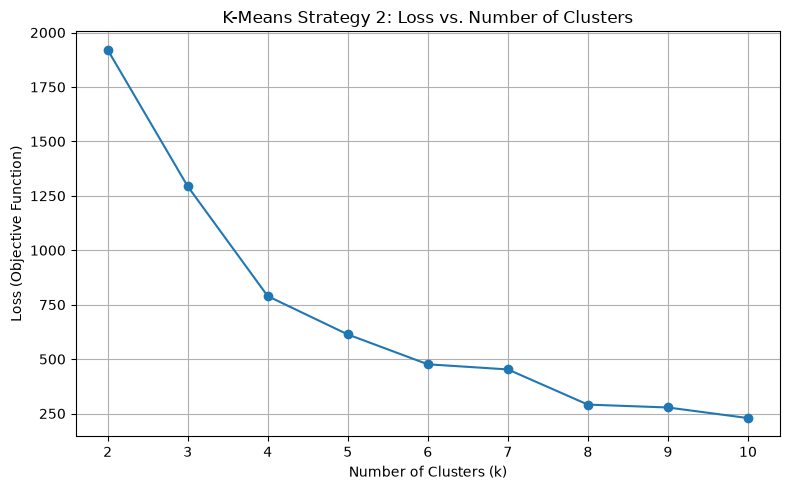

In [6]:
# Plot the final K-means loss for k = 2 through 10.
import matplotlib.pyplot as plt

k_values = list(range(2, 11))
loss_values = [losses[k] for k in k_values]

plt.figure(figsize=(8, 5))
plt.plot(k_values, loss_values, marker='o')
plt.xticks(k_values)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Loss (Objective Function)')
plt.title('K-Means Strategy 2: Loss vs. Number of Clusters')
plt.grid(True)
plt.tight_layout()
plt.show()

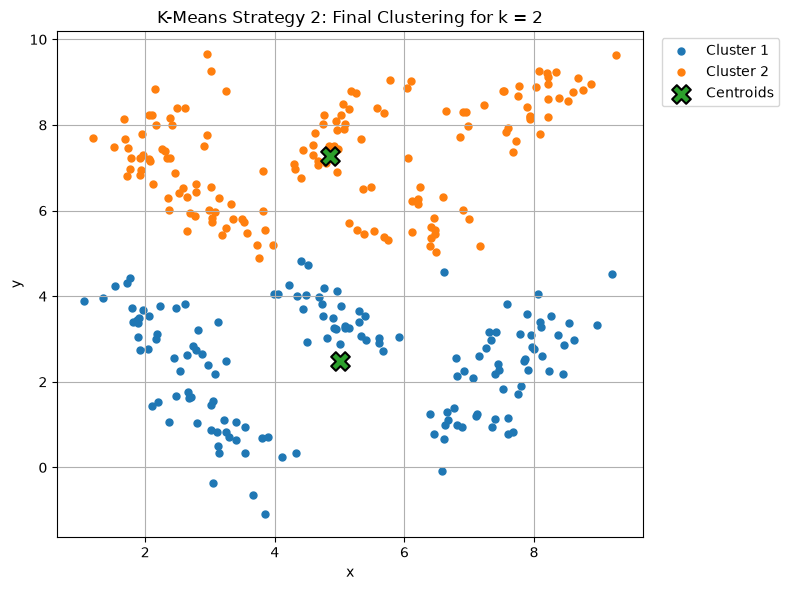

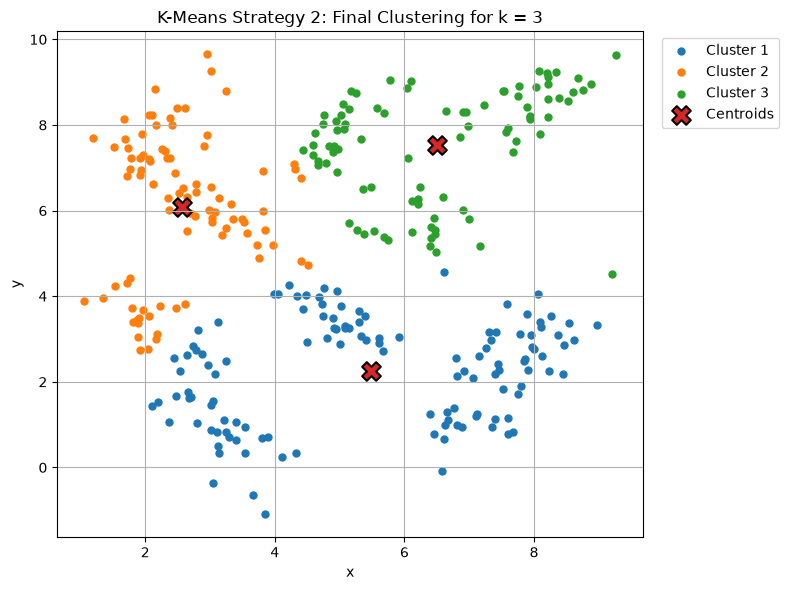

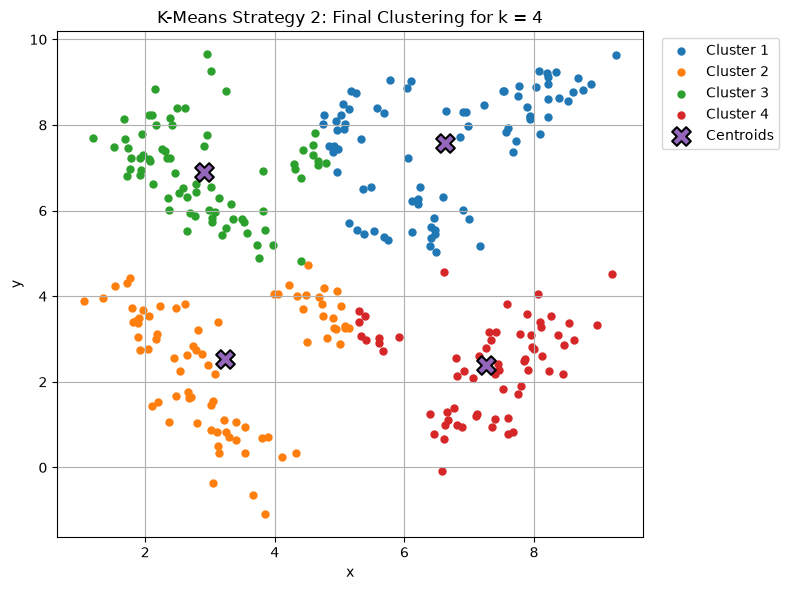

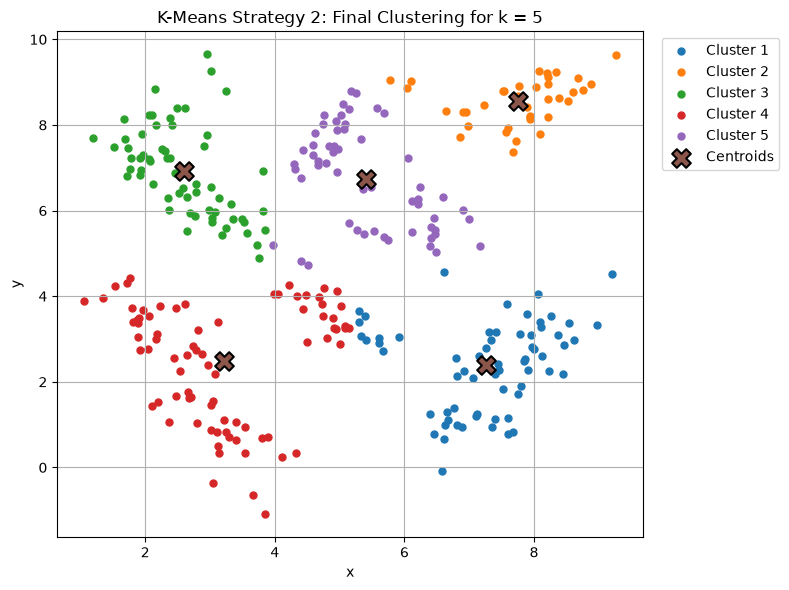

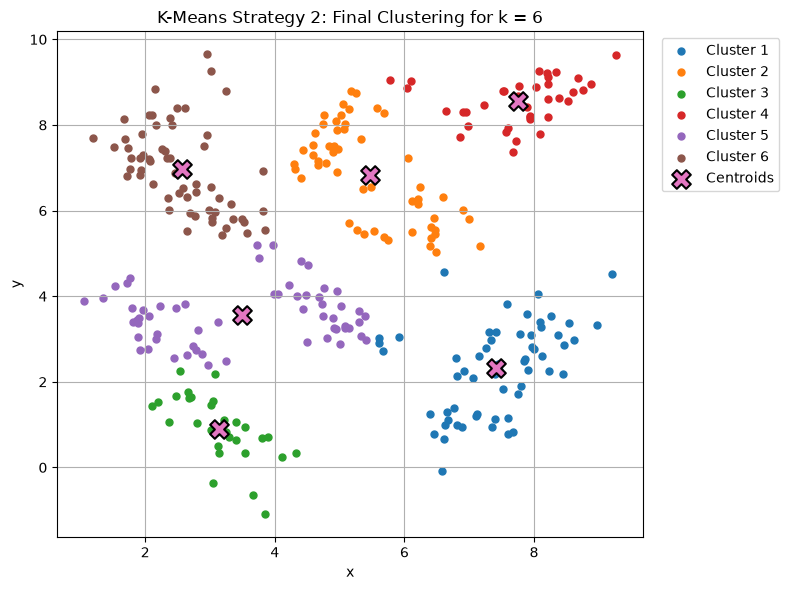

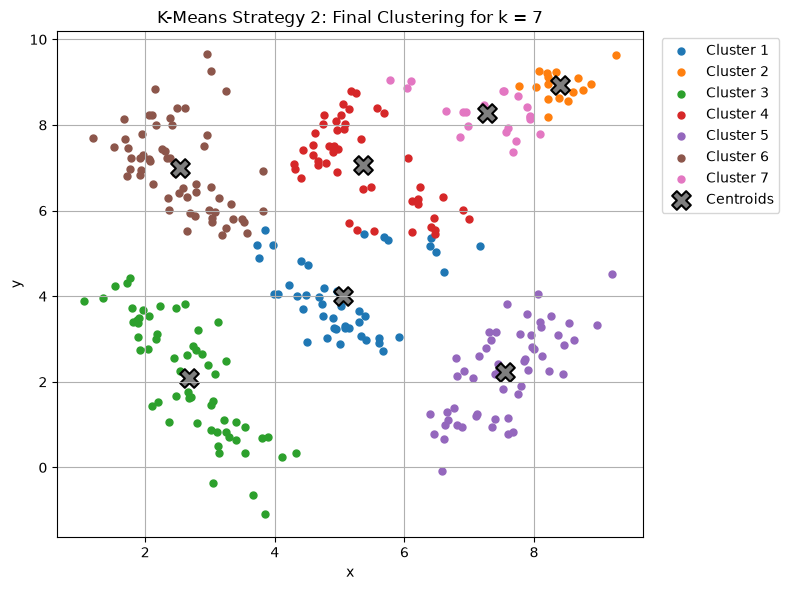

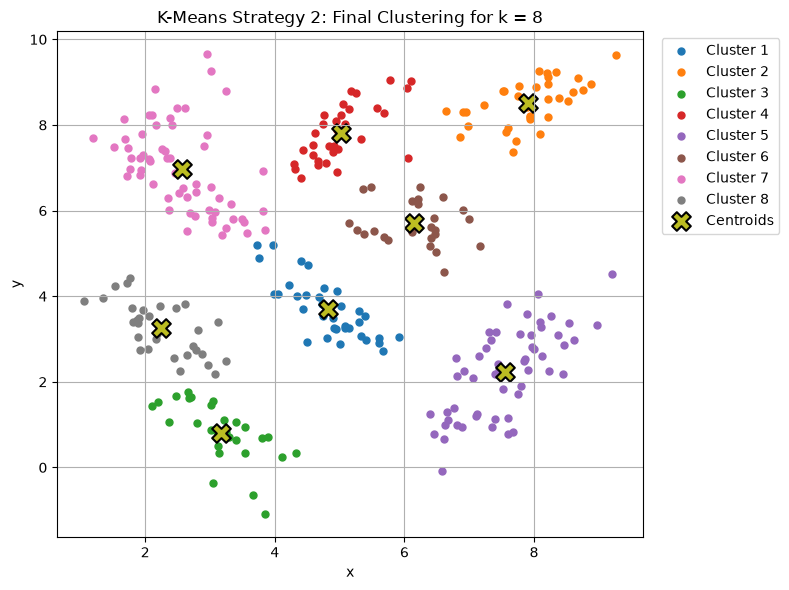

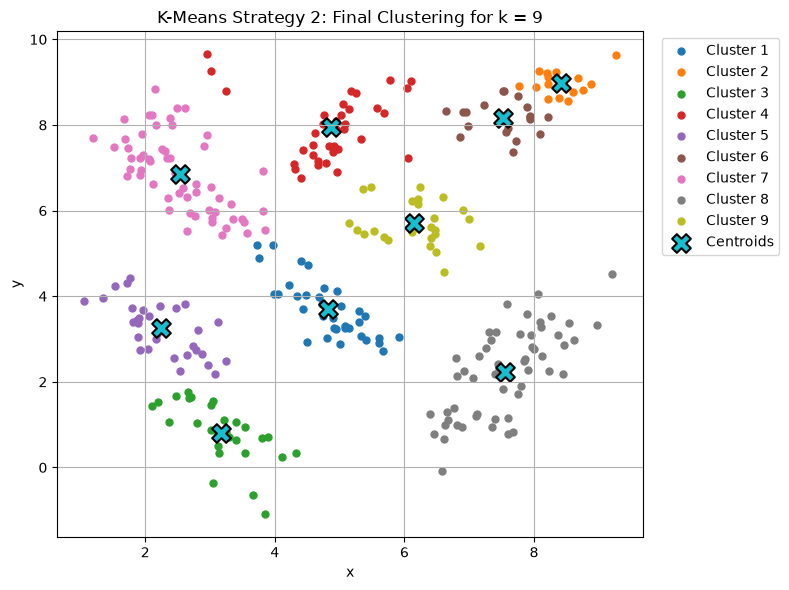

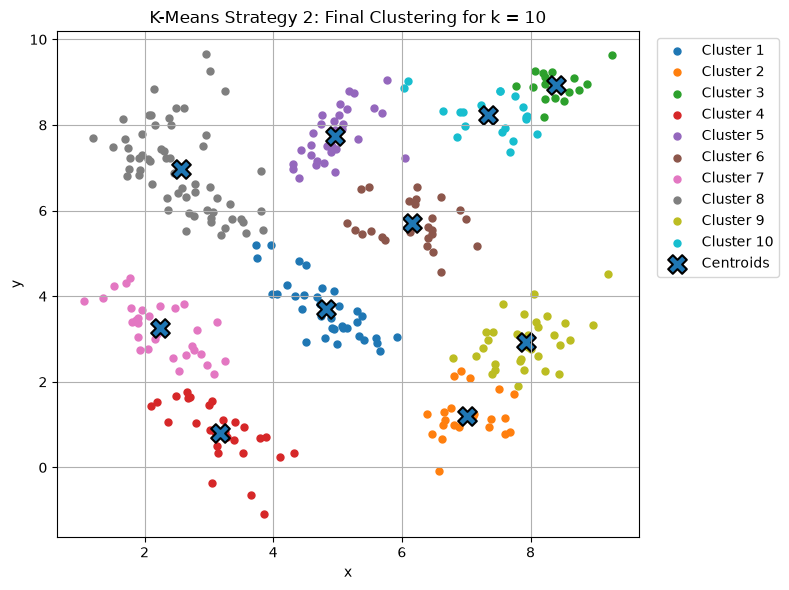

In [7]:
# Plot the final clustering and centroids for each value of k.
for k in range(2, 11):
    labels = final_labels[k]
    centroids = final_centroids[k]

    plt.figure(figsize=(8, 6))

    # Plot the points assigned to each cluster separately.
    for cluster_index in range(k):
        cluster_points = data[labels == cluster_index]

        plt.scatter(
            cluster_points[:, 0],
            cluster_points[:, 1],
            s=25,
            label=f'Cluster {cluster_index + 1}'
        )

    # Overlay the final cluster centroids.
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker='X',
        s=180,
        edgecolors='black',
        linewidths=1.5,
        label='Centroids'
    )

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'K-Means Strategy 2: Final Clustering for k = {k}')
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc='upper left'
    )
    plt.grid(True)
    plt.tight_layout()
    plt.show()